In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, StrMethodFormatter

BASE_DIR = Path("preprint_results/random_k_half_exact_relu_elu_3")
EXTENDED_DIR = Path("preprint_results/random_k_half_extended_N50_125")
COMBINED_GRID_PATH = BASE_DIR / "random_initial_grid_combined_to_K24000.csv"
COMBINED_SUMMARY_PATH = BASE_DIR / "random_initial_K_half_combined_to_K24000.csv"
THRESHOLD = 0.5

plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 450,
        "savefig.facecolor": "white",
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "semibold",
        "axes.labelsize": 11,
        "axes.labelcolor": "#111827",
        "axes.edgecolor": "#9ca3af",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e5e7eb",
        "grid.linewidth": 0.8,
        "grid.alpha": 0.9,
        "legend.frameon": False,
        "xtick.color": "#374151",
        "ytick.color": "#374151",
        "lines.linewidth": 2.4,
        "lines.markersize": 6,
    }
)

COLORS = {"relu": "#2563eb", "elu": "#dc2626", "step": "#111827"}
MARKERS = {"relu": "o", "elu": "s", "step": "^"}


In [6]:
def _finish(fig, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout(pad=1.2)
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()


def _style_axis(ax):
    ax.set_facecolor("#ffffff")
    ax.grid(True, axis="y", color="#e5e7eb", linewidth=0.8)
    ax.grid(True, axis="x", color="#f3f4f6", linewidth=0.6)
    ax.tick_params(axis="both", length=0, pad=6)


def _format_k_axis(ax):
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    _style_axis(ax)


def _threshold_label(threshold):
    return f"{threshold:.0%} recovery threshold"


def plot_random_initial_grid(df, output_path, threshold=THRESHOLD):
    activations = sorted(df["activation"].unique())
    fig, axes = plt.subplots(
        len(activations),
        1,
        figsize=(10.4, 4.3 * len(activations)),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for ax, activation in zip(axes[:, 0], activations):
        act_group = df[df["activation"] == activation]
        ns = sorted(act_group["N"].unique())
        cmap = plt.get_cmap("cividis")
        n_colors = {n: cmap(i / max(len(ns) - 1, 1)) for i, n in enumerate(ns)}

        for n_value in ns:
            group = act_group[act_group["N"] == n_value].sort_values("K")
            ax.errorbar(
                group["K"],
                group["recovery_fraction"],
                yerr=group["standard_error"],
                marker="o",
                linewidth=2.1,
                capsize=2.8,
                capthick=1.0,
                elinewidth=1.0,
                color=n_colors[n_value],
                label=f"N={n_value}",
            )

        ax.axhline(threshold, color="#111827", linestyle="--", linewidth=1.35, label=_threshold_label(threshold))
        ax.set_title(f"{activation.upper()} random-initial recovery to K=24,000", loc="left")
        ax.set_ylabel("Recovery fraction")
        ax.set_ylim(-0.03, 1.03)
        ax.set_xlim(left=0)
        ax.legend(ncol=4, fontsize=9, loc="upper right", handlelength=1.7, columnspacing=1.0)
        _format_k_axis(ax)

    axes[-1, 0].set_xlabel("Stored memories K")
    _finish(fig, output_path)


def plot_k_half(summary, output_path):
    fig, ax = plt.subplots(figsize=(8.9, 5.4))

    for activation, group in summary.groupby("activation"):
        group = group.sort_values("N")
        color = COLORS.get(activation, None)
        marker = MARKERS.get(activation, "o")
        measured = group[~group["K_half_upper_is_lower_bound"]]
        lower_bounds = group[group["K_half_upper_is_lower_bound"]]

        if not measured.empty:
            ax.plot(
                measured["N"],
                measured["K_half_upper_capacity"],
                marker=marker,
                color=color,
                markeredgecolor="white",
                markeredgewidth=0.9,
                label=activation.upper(),
            )
        if not lower_bounds.empty:
            ax.scatter(
                lower_bounds["N"],
                lower_bounds["K_half_upper_capacity"],
                marker="^",
                s=90,
                color=color,
                edgecolor="white",
                linewidth=0.8,
                label=f"{activation.upper()} lower bound",
            )

    ax.set_title("Random-initial K1/2 capacity to K=24,000", loc="left")
    ax.set_xlabel("Network size N")
    ax.set_ylabel("Upper K1/2 capacity")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.legend(ncol=2, fontsize=9, handlelength=1.8, columnspacing=1.2)
    _style_axis(ax)
    _finish(fig, output_path)


def plot_k_half_loglog(summary, output_path):
    fig, ax = plt.subplots(figsize=(8.9, 5.4))
    fit_rows = []

    for activation, group in summary.groupby("activation"):
        finite_group = group[
            group["K_half_upper_capacity"].notna() & (group["K_half_upper_capacity"] > 0)
        ].sort_values("N")
        if finite_group.empty:
            continue

        color = COLORS.get(activation, None)
        marker = MARKERS.get(activation, "o")
        ax.scatter(
            finite_group["N"],
            finite_group["K_half_upper_capacity"],
            marker=marker,
            s=66,
            color=color,
            edgecolor="white",
            linewidth=0.9,
            label=f"{activation.upper()} K1/2",
        )

        fit_group = finite_group[~finite_group["K_half_upper_is_lower_bound"]]
        if len(fit_group) >= 2:
            log_n = np.log10(fit_group["N"].to_numpy(dtype=float))
            log_k = np.log10(fit_group["K_half_upper_capacity"].to_numpy(dtype=float))
            slope, intercept = np.polyfit(log_n, log_k, deg=1)
            x_fit = np.linspace(fit_group["N"].min(), fit_group["N"].max(), 200)
            y_fit = 10 ** intercept * x_fit**slope
            ax.plot(x_fit, y_fit, color=color, linewidth=2.2, alpha=0.82, label=f"{activation.upper()} slope={slope:.2f}")
            fit_rows.append(
                {
                    "activation": activation,
                    "slope": slope,
                    "intercept": intercept,
                    "coefficient": 10 ** intercept,
                    "n_points": len(fit_group),
                    "min_N": fit_group["N"].min(),
                    "max_N": fit_group["N"].max(),
                }
            )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title("Power-law scaling of random-initial K1/2", loc="left")
    ax.set_xlabel("Network size N")
    ax.set_ylabel("Upper K1/2 capacity")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.legend(ncol=2, fontsize=9, handlelength=1.8, columnspacing=1.2)
    _style_axis(ax)
    _finish(fig, output_path)
    return pd.DataFrame(fit_rows)


In [7]:
def _as_bool(series):
    if series.dtype == bool:
        return series
    return series.astype(str).str.lower().isin(["true", "1", "yes"])


def merge_extended_results(base_dir=BASE_DIR, extended_dir=EXTENDED_DIR):
    base_dir = Path(base_dir)
    extended_dir = Path(extended_dir)

    base_grid = pd.read_csv(base_dir / "random_initial_grid.csv")
    ext_grid = pd.read_csv(extended_dir / "random_initial_grid.csv")
    combined_grid = (
        pd.concat([base_grid, ext_grid], ignore_index=True)
        .sort_values(["activation", "N", "K"])
        .drop_duplicates(["activation", "N", "K"], keep="last")
        .reset_index(drop=True)
    )

    base_summary = pd.read_csv(base_dir / "random_initial_K_half.csv")
    ext_summary = pd.read_csv(extended_dir / "random_initial_K_half.csv")
    base_summary["source"] = "base_to_K5000"
    ext_summary["source"] = "extended_to_K24000"
    combined_summary = (
        pd.concat([base_summary, ext_summary], ignore_index=True)
        .assign(K_half_upper_is_lower_bound=lambda d: _as_bool(d["K_half_upper_is_lower_bound"]))
        .sort_values(["activation", "N", "K_half_upper_capacity", "source"])
        .drop_duplicates(["activation", "N"], keep="last")
        .sort_values(["activation", "N"])
        .reset_index(drop=True)
    )

    combined_grid.to_csv(COMBINED_GRID_PATH, index=False)
    combined_summary.to_csv(COMBINED_SUMMARY_PATH, index=False)
    return combined_grid, combined_summary

combined_grid, combined_summary = merge_extended_results()
print(f"Combined grid rows: {len(combined_grid)}")
print(f"Combined grid saved to: {COMBINED_GRID_PATH}")
print(f"Combined summary saved to: {COMBINED_SUMMARY_PATH}")
print(combined_grid.groupby(["activation", "N"])["K"].agg(["min", "max", "nunique"]))
combined_summary


Combined grid rows: 364
Combined grid saved to: preprint_results/random_k_half_exact_relu_elu_3/random_initial_grid_combined_to_K24000.csv
Combined summary saved to: preprint_results/random_k_half_exact_relu_elu_3/random_initial_K_half_combined_to_K24000.csv
                min    max  nunique
activation N                       
elu        50    50  24000       26
           75    50  24000       26
           100   50  24000       26
           125   50  24000       26
           150   50  24000       26
           175   50  24000       26
           200   50  24000       26
relu       50    50  24000       26
           75    50  24000       26
           100   50  24000       26
           125   50  24000       26
           150   50  24000       26
           175   50  24000       26
           200   50  24000       26


,N,activation,activation_threshold_k,K_half_first_crossing,K_half_upper_capacity,K_half_upper_is_lower_bound,threshold,max_observed_recovery_fraction,source,dam_power
0,50,elu,0.2,NaN,NaN,False,0.5,0.000,extended_to_K24000,NaN
1,75,elu,0.2,NaN,NaN,False,0.5,0.000,extended_to_K24000,NaN
2,100,elu,0.2,NaN,NaN,False,0.5,0.038,extended_to_K24000,NaN
3,125,elu,0.2,NaN,NaN,False,0.5,0.390,extended_to_K24000,NaN
4,150,elu,0.2,5000.0,7518.518519,False,0.5,0.651,base_to_K5000,NaN
5,175,elu,0.2,5000.0,13690.140845,False,0.5,0.715,base_to_K5000,NaN
6,200,elu,0.2,5000.0,23708.333333,False,0.5,0.727,base_to_K5000,NaN
7,50,relu,0.2,NaN,NaN,False,0.5,0.000,extended_to_K24000,NaN
8,75,relu,0.2,NaN,NaN,False,0.5,0.000,extended_to_K24000,NaN
9,100,relu,0.2,NaN,NaN,False,0.5,0.052,extended_to_K24000,NaN


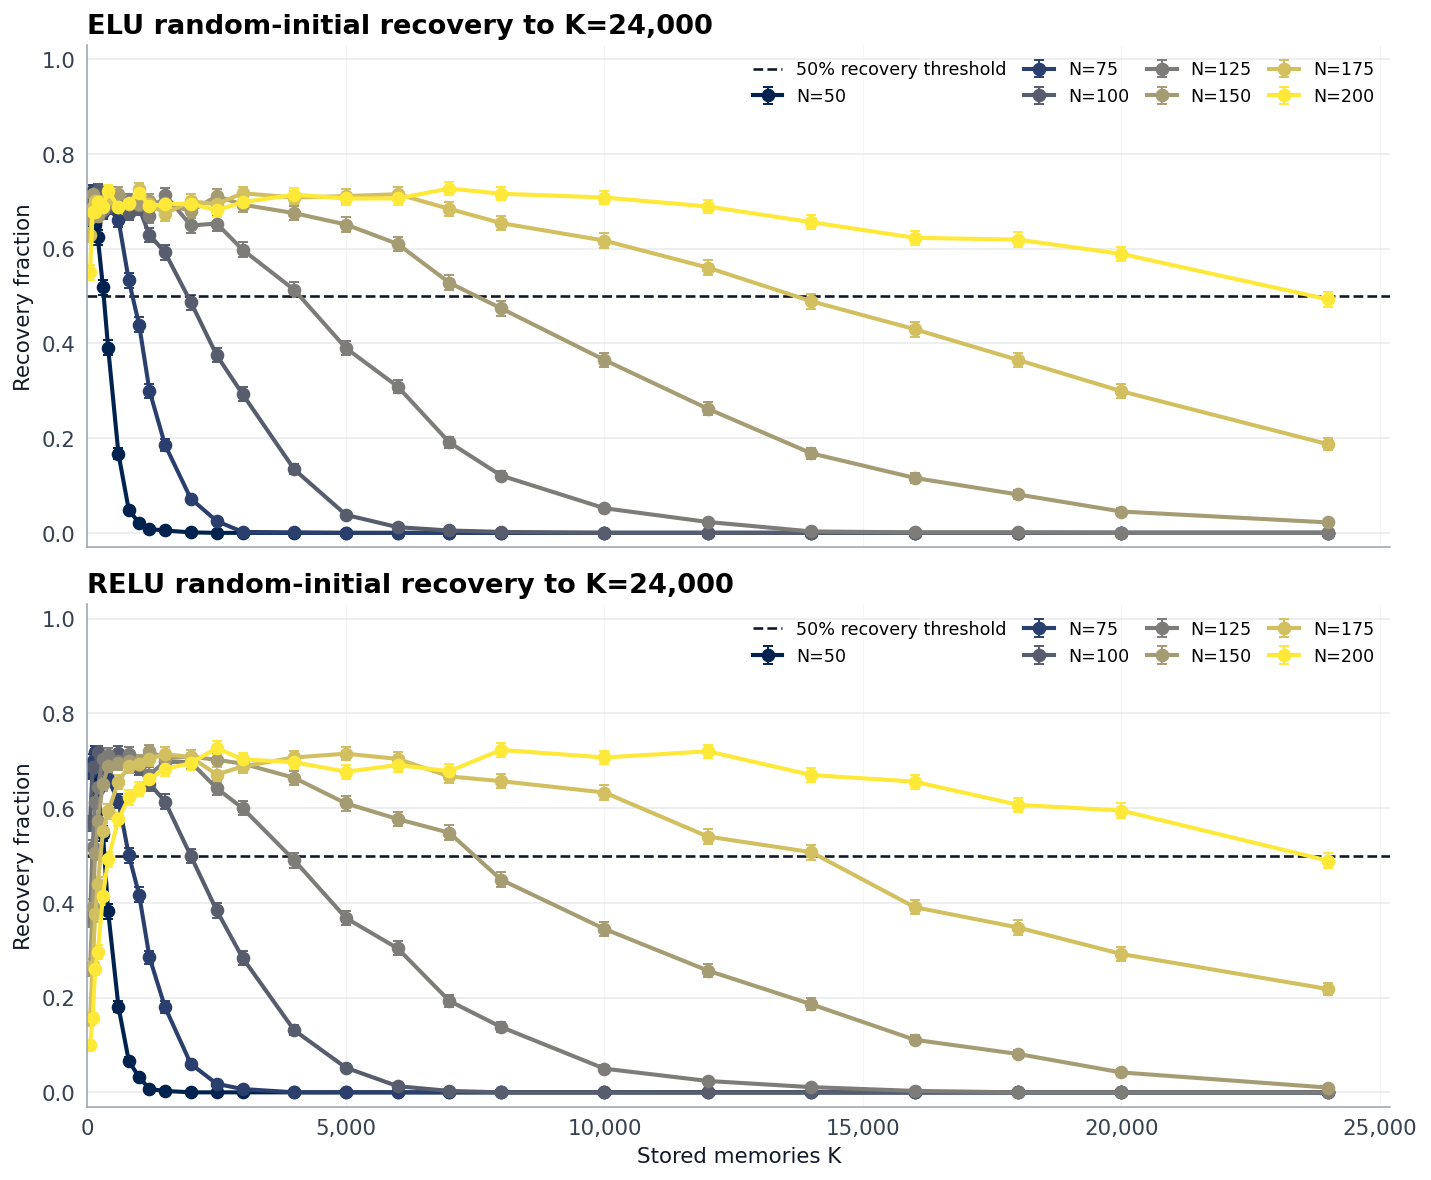

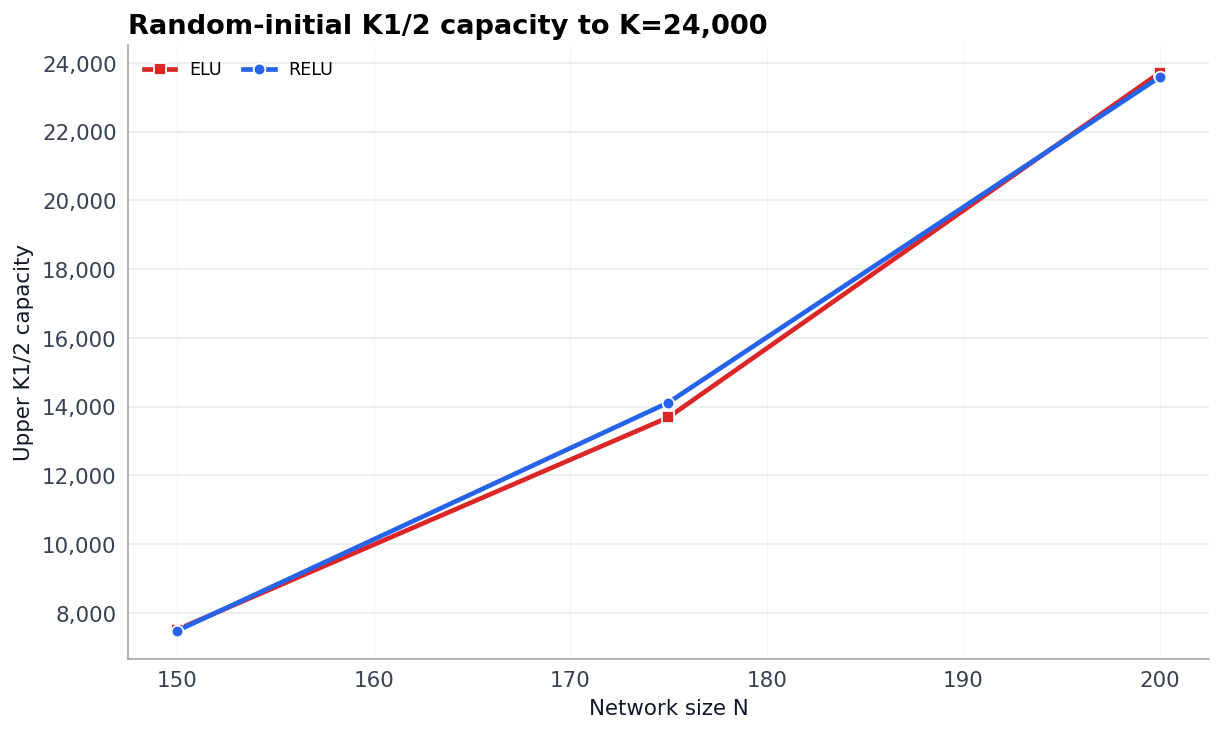

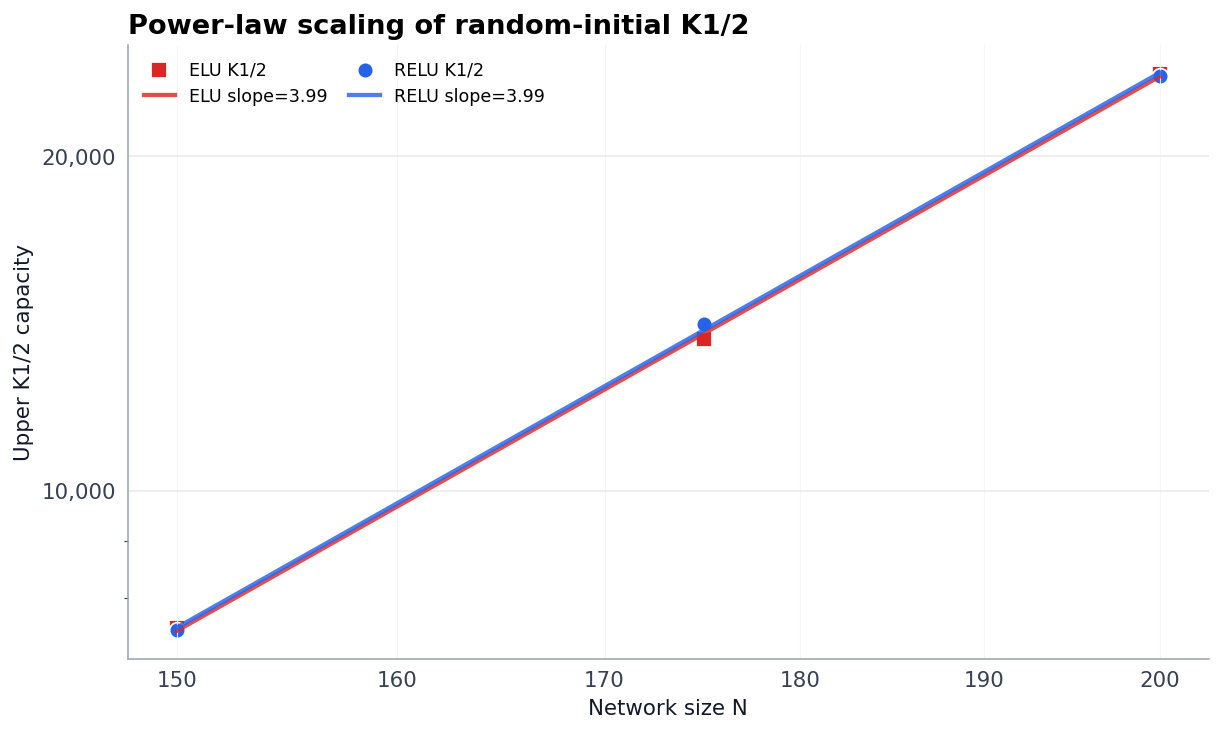

,activation,slope,intercept,coefficient,n_points,min_N,max_N
0,elu,3.989440,-4.807411,0.000016,3,150,200
1,relu,3.992842,-4.811953,0.000015,3,150,200


In [8]:
plot_random_initial_grid(combined_grid, BASE_DIR / "random_initial_recovery_grid.png", THRESHOLD)
plot_k_half(combined_summary, BASE_DIR / "K_half_vs_N.png")
fit_summary = plot_k_half_loglog(combined_summary, BASE_DIR / "K_half_vs_N_loglog.png")
fit_summary.to_csv(BASE_DIR / "K_half_power_law_fit.csv", index=False)
fit_summary
